# 🚀 Tweet Bencana (*Disaster Tweets*) — Meningkatkan Baseline (RoBERTa + Validasi Silang + Ensemble)

> **Notebook 2 dari 2.** Target: mengalahkan skor baseline **0.83389** (DistilBERT, satu kali pembagian 80/20).

## 🎯 Ringkasan perubahan

| # | Perubahan | Masalah di baseline yang diperbaiki | Cara kerja singkat |
|---|---|---|---|
| 1 | **Perbaikan label duplikat** | Tweet identik muncul dengan label berbeda | Ambil suara terbanyak; buang yang seri; hapus duplikat |
| 2 | **Normalisasi teks** | URL, `@user`, `&amp;` menjadi token tak berguna | URL → `http`, mention → `@user`, HTML entity di-decode |
| 3 | **Memakai kolom `keyword`** | Petunjuk berguna diabaikan | Input pasangan: `keyword` + `teks` |
| 4 | **Model lebih besar: RoBERTa-base** | DistilBERT berkapasitas kecil | Ganti satu nama model (bisa ditambah model lain) |
| 5 | **K-Fold berstrata (*Stratified K-Fold*, 5 lipatan)** | Hanya satu pembagian data, 20% data tak terpakai belajar | Tiap data jadi validasi tepat sekali; semua data dipakai melatih |
| 6 | **Ensemble (penggabungan model) antar-fold, seed, dan model** | Satu model → variansi tinggi | Rata-rata probabilitas 5 model (atau lebih) |
| 7 | **Pelunakan label (*label smoothing*)** | Model terlalu yakin pada label berisik | Target "lembut" (0.95 / 0.05), bukan 1 / 0 |
| 8 | **Optimasi ambang F1** | Ambang tetap 0.5 | Cari ambang terbaik pada prediksi *out-of-fold* (OOF, prediksi data saat ia berada di lipatan validasi) |
| 9 | **Tanpa weight decay pada bias & LayerNorm** | Praktik standar fine-tuning | Dua grup parameter di optimizer |

> ⚠️ **Ekspektasi yang jujur.** Dataset ini punya label berisik (*label noise*) sehingga skor umumnya mentok di kisaran 0.84–0.86 (bahkan untuk model besar). Peningkatan realistis adalah **beberapa per mil sampai ±1–2 poin**, dan tidak dijamin. *Public leaderboard* hanya memakai sebagian data test, jadi selisih ±0.003–0.005 antar-submission bisa murni *noise*.
> Notebook ini juga **belum dijalankan oleh penulisnya** pada data aslimu — kalau ada error, kirim pesannya agar diperbaiki.

---

## 📑 Daftar isi
1. [Persiapan & konfigurasi](#1.-Persiapan-&-konfigurasi)
2. [Memuat data](#2.-Memuat-data)
3. [Pembersihan data & label](#3.-Pembersihan-data-&-label)
4. [Model, tokenizer & DataLoader](#4.-Model,-tokenizer-&-DataLoader)
5. [Fungsi pelatihan satu fold](#5.-Fungsi-pelatihan-satu-fold)
6. [Menjalankan validasi silang](#6.-Menjalankan-validasi-silang)
7. [Evaluasi & ambang optimal](#7.-Evaluasi-&-ambang-optimal)
8. [Membuat file submission](#8.-Membuat-file-submission)
9. [Langkah berikutnya](#9.-Langkah-berikutnya)

## 🗺️ Alur keseluruhan

```text
train.csv ─► normalisasi ─► perbaiki label duplikat ─► [keyword + teks]
                                                            │
                                     StratifiedKFold (5 lipatan)
                                                            │
        ┌────────────── tiap fold ───────────────┐         │
        │  latih RoBERTa di 4/5 data             │◄────────┘
        │  validasi di 1/5 data  → prob. OOF    │
        │  prediksi data uji     → prob. uji    │
        └────────────────────────────────────────┘
                     │                    │
          gabungan OOF (semua data)   rata-rata prob. uji (5 model)
                     │                    │
          cari ambang F1 terbaik ──────► submission.csv
```

## 🔎 Cara membaca
Sama seperti notebook 1: setiap baris kode diberi komentar `#`, dan markdown menjelaskan konsepnya. `> 💡` tips · `> ⚠️` peringatan · `> 🧠` intuisi.

# 1. Persiapan & konfigurasi

## Penjelasan hyperparameter

| Nama | Nilai | Arti & alasan |
|---|---|---|
| `MODEL_NAMES` | `["roberta-base"]` | Daftar model yang di-ensemble. RoBERTa dilatih lebih lama dan di data lebih besar daripada BERT, dan biasanya lebih kuat untuk teks media sosial |
| `SEEDS` | `[42]` | Tiap seed = satu rangkaian K-Fold baru. Tambah seed → ensemble lebih stabil, waktu naik linear |
| `N_FOLDS` | 5 | Jumlah lipatan; tiap model dilatih 5 kali |
| `EPOCHS` | 3 | Dataset kecil, 2–4 epoch cukup; bobot terbaik per fold dipilih dari F1 validasi |
| `BATCH_SIZE` | 16 | Batch kecil memberi update lebih sering & regularisasi alami pada data kecil |
| `LR` | 2e-5 | Nilai klasik untuk fine-tuning model berukuran base |
| `MAX_LEN` | 96 | Tweet + keyword jarang melewati 96 token; lebih kecil dari baseline = lebih cepat |
| `LABEL_SMOOTHING` | 0.1 | Target jadi 0.95/0.05 untuk 2 kelas, meredam efek label salah |
| `DEBUG` | `False` | `True` = jalankan versi mini (data kecil, 2 fold, 1 epoch) untuk mengetes pipeline dalam hitungan menit |

**Pelunakan label** (*label smoothing*) mengganti target one-hot $y$ dengan $\tilde y = (1-\varepsilon)\,y + \varepsilon/K$, dengan $K=2$ kelas dan $\varepsilon=0.1$:

$$\tilde y_{\text{benar}}=0.95,\qquad \tilde y_{\text{salah}}=0.05$$

> 💡 **Menjalankan pertama kali?** Set `DEBUG = True` dulu. Kalau seluruh notebook sampai bagian submission berjalan tanpa error, baru ubah ke `False`.

> ⚠️ **Butuh GPU.** Lima kali fine-tuning RoBERTa-base di CPU sangat lama dan tidak praktis. Di Kaggle, aktifkan *Accelerator → GPU*.

In [1]:
# !pip install -q torch transformers scikit-learn pandas matplotlib tqdm   # (opsional) pasang library jika belum ada

import os                      # operasi path & folder
import gc                      # garbage collector: membebaskan memori antar-fold
import re                      # regular expression untuk membersihkan teks
import html                    # html.unescape: &amp; → &
import random                  # keacakan Python
import contextlib              # nullcontext untuk mode tanpa AMP

import numpy as np             # array numerik
import pandas as pd            # tabel data
import torch                   # inti deep learning
import torch.nn as nn          # nn.CrossEntropyLoss
from torch.utils.data import Dataset, DataLoader         # penyusun batch
from transformers import (
    AutoTokenizer,                                       # tokenizer otomatis sesuai model
    AutoModelForSequenceClassification,                  # model + head klasifikasi
    get_linear_schedule_with_warmup,                     # jadwal LR: warmup lalu turun linear
)
from sklearn.model_selection import StratifiedKFold      # K-Fold yang menjaga proporsi kelas di tiap lipatan
from sklearn.metrics import ConfusionMatrixDisplay, f1_score    # metrik & plot
import matplotlib.pyplot as plt                          # grafik
from tqdm.auto import tqdm                               # bilah kemajuan

import transformers                                      # untuk mencetak versi
print("Torch:", torch.__version__, "| Transformers:", transformers.__version__)   # cetak versi library

C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Torch: 2.11.0+cu128 | Transformers: 5.14.1


In [2]:
# ===== Konfigurasi utama =====
MODEL_NAMES = ["roberta-base"]              # model yang akan dilatih & di-ensemble (lihat bagian 9 untuk ide model lain)
LOCAL_DIRS = {                              # (opsional) folder lokal format Hugging Face untuk tiap model
    "roberta-base": "../pretrained/roberta_base",   # jika folder ini valid → dipakai; jika tidak → unduh dari Hub
}

SEEDS = [42]                                # daftar seed; tiap seed = satu kali K-Fold lengkap
N_FOLDS = 5                                 # jumlah lipatan cross-validation
EPOCHS = 3                                  # epoch per fold
BATCH_SIZE = 16                             # ukuran batch train
LR = 2e-5                                   # learning rate puncak
WEIGHT_DECAY = 0.01                         # regularisasi L2 (tidak untuk bias & LayerNorm)
WARMUP_RATIO = 0.1                          # 10% langkah awal untuk warmup
MAX_LEN = 96                                # batas token per input (keyword + tweet)
LABEL_SMOOTHING = 0.1                       # ε pada label smoothing
DEBUG = False                               # True → versi mini untuk tes pipeline

if DEBUG:                                   # mode tes cepat
    N_FOLDS, EPOCHS = 2, 1                  #   cukup 2 fold & 1 epoch
    print("⚠️ DEBUG aktif: hasil TIDAK untuk disubmit.")   # peringatan


def set_seed(seed):                         # kunci semua sumber keacakan
    random.seed(seed)                       #   Python
    np.random.seed(seed)                    #   NumPy
    torch.manual_seed(seed)                 #   PyTorch CPU
    torch.cuda.manual_seed_all(seed)        #   PyTorch GPU (aman walau tanpa GPU)

if torch.cuda.is_available():               # GPU NVIDIA tersedia?
    device = torch.device("cuda")           #   pakai GPU
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():   # Apple GPU?
    device = torch.device("mps")            #   pakai MPS
else:                                       # selain itu
    device = torch.device("cpu")            #   CPU (sangat lambat untuk notebook ini)
use_amp = device.type == "cuda"             # fp16 hanya di GPU NVIDIA
print("Perangkat:", device, "| AMP:", use_amp) # tampilkan

Perangkat: cuda | AMP: True


# 2. Memuat data
Sama seperti baseline: `find_file` mencari di folder kerja lalu di folder input Kaggle.

In [3]:
KAGGLE_DIR = "/kaggle/input/nlp-getting-started"     # lokasi data di Kaggle

def find_file(filename):                              # cari file di beberapa folder kandidat
    for folder in [".", KAGGLE_DIR]:                  #   coba folder kerja, lalu folder Kaggle
        path = os.path.join(folder, filename)         #     bentuk path lengkap
        if os.path.exists(path):                      #     ada?
            return path                               #       kembalikan
    raise FileNotFoundError(f"{filename} tidak ditemukan")   # tidak ada di mana pun

df_train = pd.read_csv(find_file("train.csv"))        # data latih
df_test = pd.read_csv(find_file("test.csv"))          # data uji

if DEBUG:                                             # mode tes cepat → kecilkan data
    df_train = df_train.sample(400, random_state=0).reset_index(drop=True)   # 400 baris acak
    df_test = df_test.head(200).reset_index(drop=True)                       # 200 baris pertama

print("Latih:", df_train.shape, "| Uji:", df_test.shape)   # cek ukuran

Latih: (7613, 5) | Uji: (3263, 4)


# 3. Pembersihan data & label

## 3.1 Normalisasi teks (perubahan #2)

Model Transformer sudah tahan terhadap teks mentah, jadi pembersihan dibuat **minimal & aman** (tidak membuang stopword, tidak mengubah huruf besar-kecil):

| Pola | Contoh | Menjadi | Alasan |
|---|---|---|---|
| HTML entity | `&amp;`, `&lt;` | `&`, `<` | Sisa encoding dari sumber data |
| URL | `https://t.co/AbC123` | `http` | Isi URL acak tak bermakna; *keberadaan* link tetap informatif |
| Mention | `@BBCBreaking` | `@user` | Nama akun jarang membantu & membuat vocab berisik |
| Spasi berlebih | `a   b` | `a b` | Kerapian |

Hashtag **tidak** dihapus karena sering berisi kata kunci (`#earthquake`).

## 3.2 Label tidak konsisten (perubahan #1)

Di data latih ada tweet yang **teksnya sama persis tetapi labelnya berbeda**. Model dipaksa mempelajari dua jawaban untuk satu input. Strateginya:

```text
Kelompokkan tweet dengan teks (ternormalisasi) sama
 ├─ semua label sama            → biarkan
 ├─ label berbeda, mayoritas jelas → seragamkan ke label mayoritas
 └─ label berbeda, seri (50:50) → buang seluruh kelompok (ambigu)
Lalu hapus duplikat, sisakan satu baris per teks
```

> 🧠 Menghapus duplikat juga mencegah **kebocoran antar-fold**: tweet yang sama tidak mungkin muncul sekaligus di data latih dan validasi.

> 💡 Setelah label dibersihkan, F1 *out-of-fold* tidak persis sebanding dengan skor Kaggle (label train sudah diubah, label test tidak). Pakai F1 OOF untuk **membandingkan konfigurasi**, bukan untuk memperkirakan skor leaderboard secara absolut.

In [4]:
def normalize_tweet(text):                                    # fungsi pembersih teks minimal
    text = html.unescape(str(text))                           #   &amp; → &  ; str() menjaga agar NaN tak membuat error
    text = re.sub(r"https?://\S+|www\.\S+", "http", text)     #   semua URL (http/https/www) → kata "http"
    text = re.sub(r"@\w+", "@user", text)                     #   semua mention @nama → "@user"
    text = re.sub(r"\s+", " ", text).strip()                  #   rapikan spasi berlebih & spasi di tepi
    return text                                               #   hasil bersih


# --- Lihat dulu contoh normalisasi ---
for t in df_train["text"].head(3):                            # ambil 3 tweet pertama
    print("ASLI :", t)                                        #   sebelum
    print("BERSIH:", normalize_tweet(t), "\n")                #   sesudah

ASLI : Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all
BERSIH: Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all 

ASLI : Forest fire near La Ronge Sask. Canada
BERSIH: Forest fire near La Ronge Sask. Canada 

ASLI : All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected
BERSIH: All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected 



In [5]:
df_train["text_norm"] = df_train["text"].map(normalize_tweet)     # teks ternormalisasi untuk train
df_test["text_norm"] = df_test["text"].map(normalize_tweet)       # idem untuk test

grp = df_train.groupby("text_norm")["target"]                     # kelompokkan baris berdasarkan teks yang sama
df_train["dup_n"] = grp.transform("size")                         # berapa kali teks itu muncul
df_train["dup_mean"] = grp.transform("mean")                      # rata-rata label di kelompok (0=semua 0, 1=semua 1, di antaranya=campur)

conflict = (df_train["dup_n"] > 1) & (df_train["dup_mean"] > 0) & (df_train["dup_mean"] < 1)   # duplikat DENGAN label berbeda
tie = conflict & (df_train["dup_mean"] == 0.5)                    # sub-kasus seri 50:50

print(f"Baris dengan label bertentangan: {conflict.sum()} | di antaranya seri: {tie.sum()}")   # statistik
df_train.loc[conflict, ["text", "target"]].sort_values("text").head(10)   # tampilkan contoh pertentangan

Baris dengan label bertentangan: 241 | di antaranya seri: 74


,text,target
5823,#360WiseNews : China's Stock Market Crash: Are...,1
5833,#360WiseNews : China's Stock Market Crash: Are...,1
5817,#360WiseNews : China's Stock Market Crash: Are...,0
5837,#360WiseNews : China's Stock Market Crash: Are...,0
4312,#Allah describes piling up #wealth thinking it...,1
4299,#Allah describes piling up #wealth thinking it...,0
4290,#Allah describes piling up #wealth thinking it...,0
4221,#foodscare #offers2go #NestleIndia slips into ...,1
4239,#foodscare #offers2go #NestleIndia slips into ...,1
4244,#foodscare #offers2go #NestleIndia slips into ...,0


In [6]:
n_before = len(df_train)                                          # jumlah baris sebelum dibersihkan

df_train.loc[conflict, "target"] = (df_train.loc[conflict, "dup_mean"] > 0.5).astype(int)   # seragamkan ke label mayoritas
df_train = df_train[~tie]                                         # buang kelompok yang seri (ambigu)
df_train = df_train.drop_duplicates(subset="text_norm", keep="first").reset_index(drop=True)   # sisakan 1 baris per teks
df_train["target"] = df_train["target"].astype(int)               # pastikan label bertipe int (bukan float)

print(f"Baris data latih: {n_before} → {len(df_train)}")               # berapa baris yang hilang
print("Proporsi kelas:", df_train["target"].value_counts(normalize=True).round(3).to_dict())   # sebaran kelas setelah bersih

Baris data latih: 7613 → 6919
Proporsi kelas: {0: 0.593, 1: 0.407}


## 3.3 Menyusun input: `keyword` + teks (perubahan #3)

Kolom `keyword` (mis. `airplane%20accident`) memberi konteks tambahan. Kita kirim ke tokenizer sebagai **pasangan kalimat**:

```text
RoBERTa:  <s> airplane accident </s></s> Plane crash near airport, 3 dead </s>
           └── segmen A (keyword) ──┘     └──────── segmen B (tweet) ────────┘
```

`%20` adalah encoding URL untuk spasi, jadi diganti spasi biasa. Jika keyword kosong, segmen A dibiarkan kosong. Kolom `location` **tidak** dipakai karena banyak yang kosong dan isinya sangat tidak seragam.

In [7]:
def clean_keyword(series):                                        # fungsi: rapikan kolom keyword
    return series.fillna("").str.replace("%20", " ", regex=False).tolist()   # NaN→"" ; %20→spasi ; jadikan list

train_kw = clean_keyword(df_train["keyword"])                     # keyword tiap tweet train
train_tx = df_train["text_norm"].tolist()                         # teks bersih train
y = df_train["target"].to_numpy()                                 # label train (array 0/1)

test_kw = clean_keyword(df_test["keyword"])                       # keyword tiap tweet test
test_tx = df_test["text_norm"].tolist()                           # teks bersih test

print(f"Latih: {len(train_tx)} | Uji: {len(test_tx)}")           # cek jumlah
print("Contoh:", train_kw[0], "||", train_tx[0])                  # cek satu contoh (keyword || teks)

Latih: 6919 | Uji: 3263
Contoh:  || Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all


# 4. Model, tokenizer & DataLoader

## Pemuat model
`resolve_model_source` memakai folder lokal jika berformat Hugging Face yang valid, selain itu mengunduh dari Hub (butuh internet).

## Tokenisasi sekali di awal
Berbeda dengan baseline (tokenisasi di setiap batch), di sini seluruh teks **ditokenisasi sekali per model**, lalu `collate` hanya melakukan *padding*. Hasilnya lebih cepat karena tokenisasi tidak diulang di tiap epoch dan tiap fold.

## `Dataset` berindeks
`EncDataset` menerima **daftar indeks**, sehingga satu hasil tokenisasi bisa dipakai bersama oleh semua fold: fold ke-*k* cukup memberi indeks train dan indeks validasi yang berbeda.

> 🧠 `pad_to_multiple_of=8` membuat panjang batch kelipatan 8 sehingga Tensor Core GPU bekerja lebih efisien pada fp16.

In [8]:
def is_hf_folder(folder):                                         # cek apakah folder berisi model format Hugging Face
    if not os.path.isdir(folder):                                 #   folder tak ada?
        return False                                              #     → tidak valid
    has_config = os.path.exists(os.path.join(folder, "config.json"))   # ada config arsitektur?
    has_weights = any(os.path.exists(os.path.join(folder, f))     #   ada file bobot?
                      for f in ["model.safetensors", "pytorch_model.bin"])
    return has_config and has_weights                             #   valid jika keduanya ada


def resolve_model_source(model_name):                             # tentukan sumber model: lokal atau Hub
    local = LOCAL_DIRS.get(model_name)                            #   cari folder lokal untuk nama model ini (None jika tak ada)
    if local and is_hf_folder(local):                             #   ada dan valid?
        return local                                              #     pakai folder lokal
    return model_name                                             #   jika tidak, pakai nama Hub (unduh)


class EncDataset(Dataset):                                        # Dataset berbasis hasil tokenisasi + daftar indeks
    def __init__(self, enc, labels, indices):                     #   enc: dict of lists ; labels: array/None ; indices: indeks yang dipakai
        self.enc = enc                                            #     hasil tokenisasi seluruh data
        self.labels = labels                                      #     label (None untuk test)
        self.indices = np.asarray(indices)                        #     subset baris yang dipakai dataset ini

    def __len__(self):                                            #   jumlah contoh
        return len(self.indices)                                  #     = banyaknya indeks

    def __getitem__(self, j):                                     #   ambil contoh ke-j
        i = int(self.indices[j])                                  #     indeks asli di data penuh
        item = {k: self.enc[k][i] for k in self.enc}              #     ambil input_ids, attention_mask, dst. untuk baris i
        if self.labels is not None:                               #     jika berlabel
            item["labels"] = int(self.labels[i])                  #       sertakan label
        return item                                               #     satu contoh


def make_collate(tokenizer):                                      # pabrik fungsi collate (butuh tokenizer untuk padding)
    def collate(batch):                                           #   menggabungkan list contoh → batch tensor
        labels = [f.pop("labels") for f in batch if "labels" in f]    # keluarkan label dari tiap contoh (tokenizer.pad tak mengurus label)
        out = tokenizer.pad(                                      #   padding dinamis
            batch,                                                #     list dict {input_ids, attention_mask}
            padding=True,                                         #     pad ke panjang terpanjang di batch
            pad_to_multiple_of=8,                                 #     bulatkan ke kelipatan 8 (efisien di GPU)
            return_tensors="pt",                                  #     keluaran tensor PyTorch
        )
        if labels:                                                #   jika ada label
            out["labels"] = torch.tensor(labels, dtype=torch.long)    # tambahkan sebagai tensor int64
        return out                                                #   batch siap pakai
    return collate                                                # kembalikan fungsi collate


def make_loader(tokenizer, enc, labels, indices, shuffle, batch_size):   # buat DataLoader untuk subset indeks tertentu
    return DataLoader(
        EncDataset(enc, labels, indices),                         #   dataset berindeks
        batch_size=batch_size,                                    #   ukuran batch
        shuffle=shuffle,                                          #   acak urutan (True untuk train)
        collate_fn=make_collate(tokenizer),                       #   fungsi penyusun batch
    )


def encode(tokenizer, keywords, texts):                           # tokenisasi seluruh data sekali jalan
    enc = tokenizer(keywords, texts,                              #   dua argumen list → diperlakukan sebagai PASANGAN kalimat
                    truncation=True, max_length=MAX_LEN)          #   potong jika melebihi MAX_LEN
    return {k: v for k, v in enc.items()}                         #   ubah ke dict biasa berisi list-of-list

# 5. Fungsi pelatihan satu fold

Satu panggilan `train_one_fold` melakukan:

1. Memuat model **baru** (bobot awal pra-latih, head acak) — tiap fold harus mulai dari nol agar tidak ada kebocoran.
2. Melatih `EPOCHS` epoch dengan AdamW + warmup/decay linear + AMP + gradient clipping.
3. Setelah tiap epoch: hitung probabilitas validasi dan F1. **Jika F1 membaik**, simpan probabilitas validasi **dan** probabilitas test saat itu.
4. Membuang model dari memori, mengembalikan hasil terbaik.

> 💡 **Kenapa menyimpan *probabilitas*, bukan bobot?** Kita hanya butuh prediksi (OOF & test), jadi tidak perlu menyalin bobot model (±500 MB untuk RoBERTa-base) setiap fold.

## Perbedaan penting dari baseline
- Loss dihitung **di luar model**: `nn.CrossEntropyLoss(label_smoothing=0.1)`. Karena itu `labels` dikeluarkan dari batch sebelum dipanggil `model(**batch)`.
- Optimizer memakai **dua grup parameter**: bobot biasa (kena weight decay) dan bias/LayerNorm (tidak kena).
- Keluaran berupa **probabilitas** kelas 1: $p=\mathrm{softmax}(z)_1$, bukan hanya `argmax`, supaya bisa di-rata-rata dan diberi ambang bebas.

In [9]:
def to_device(batch):                                             # pindahkan seluruh tensor dalam batch ke device
    return {k: v.to(device) for k, v in batch.items()}            #   dict comprehension

def autocast_ctx():                                               # konteks presisi campuran
    if use_amp:                                                   #   GPU NVIDIA?
        return torch.autocast(device_type="cuda", dtype=torch.float16)   # forward dalam fp16
    return contextlib.nullcontext()                               #   selain itu presisi normal

def build_optimizer(model):                                       # buat AdamW dengan dua grup parameter
    no_decay = ["bias", "LayerNorm.weight", "layer_norm.weight"]  #   nama parameter yang tidak diberi weight decay
    groups = [
        {"params": [p for n, p in model.named_parameters()        #   grup 1: parameter yang BOLEH kena decay
                    if not any(nd in n for nd in no_decay)],
         "weight_decay": WEIGHT_DECAY},                           #     kekuatan decay normal
        {"params": [p for n, p in model.named_parameters()        #   grup 2: bias & LayerNorm
                    if any(nd in n for nd in no_decay)],
         "weight_decay": 0.0},                                    #     tanpa decay
    ]
    return torch.optim.AdamW(groups, lr=LR)                       #   optimizer dengan kedua grup


@torch.no_grad()                                                  # inferensi tanpa gradien
def predict_probs(model, loader):                                 # keluaran: P(kelas 1) tiap contoh, array (N,)
    model.eval()                                                  #   mode eval (dropout mati)
    outs = []                                                     #   wadah hasil per batch
    for batch in loader:                                          #   iterasi batch
        batch.pop("labels", None)                                 #     buang label bila ada (tidak dibutuhkan untuk prediksi)
        batch = to_device(batch)                                  #     kirim ke device
        with autocast_ctx():                                      #     fp16 bila aktif
            logits = model(**batch).logits                        #       logits (B, 2)
        outs.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu())   # softmax → ambil probabilitas kelas 1 → CPU
    return torch.cat(outs).numpy()                                #   gabung semua batch → array (N,)

In [10]:
def train_one_fold(model_name, tokenizer, enc_all, enc_test, y, tr_idx, va_idx, seed, fold):
    """Latih 1 model untuk 1 fold. Kembalikan probabilitas validasi & test dari epoch terbaik."""
    set_seed(seed * 100 + fold)                                   # seed unik tiap (seed, fold) → head klasifikasi & shuffle berbeda
    model = AutoModelForSequenceClassification.from_pretrained(   # muat model SEGAR untuk fold ini
        resolve_model_source(model_name), num_labels=2            #   sumber lokal/Hub ; 2 kelas
    ).to(device)                                                  #   kirim ke device

    train_loader = make_loader(tokenizer, enc_all, y, tr_idx, True, BATCH_SIZE)                  # loader train (diacak)
    val_loader = make_loader(tokenizer, enc_all, y, va_idx, False, BATCH_SIZE * 2)               # loader validasi
    test_loader = make_loader(tokenizer, enc_test, None, np.arange(len(enc_test["input_ids"])),  # loader test: semua baris,
                              False, BATCH_SIZE * 2)                                             #   urutan asli (tanpa shuffle)

    optimizer = build_optimizer(model)                            # AdamW dua grup
    total_steps = len(train_loader) * EPOCHS                      # total langkah training
    scheduler = get_linear_schedule_with_warmup(                  # jadwal LR
        optimizer, int(WARMUP_RATIO * total_steps), total_steps)  #   warmup 10% lalu turun linear ke 0
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)        # skala loss fp16 (nonaktif di non-GPU)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)   # cross-entropy + label smoothing

    best = {"f1": -1.0, "epoch": 0, "val_probs": None, "test_probs": None}   # rekor terbaik fold ini
    for epoch in range(1, EPOCHS + 1):                            # loop epoch
        model.train()                                             #   mode train (dropout aktif)
        pbar = tqdm(train_loader, desc=f"[{model_name}] seed {seed} fold {fold+1}/{N_FOLDS} ep {epoch}", leave=False)
        for batch in pbar:                                        #   loop batch
            labels = batch.pop("labels").to(device)               #     pisahkan label (loss dihitung manual)
            batch = to_device(batch)                              #     kirim input ke device
            optimizer.zero_grad(set_to_none=True)                 #     nolkan gradien lama
            with autocast_ctx():                                  #     forward dalam presisi campuran
                logits = model(**batch).logits                    #       logits (B, 2)
            loss = criterion(logits.float(), labels)              #     loss dihitung dalam fp32 untuk stabilitas numerik
            scaler.scale(loss).backward()                         #     backward dengan loss berskala
            scaler.unscale_(optimizer)                            #     kembalikan skala gradien sebelum clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   #   potong norma gradien ≤ 1.0
            scaler.step(optimizer)                                #     update bobot
            scaler.update()                                       #     perbarui faktor skala
            scheduler.step()                                      #     geser learning rate
            pbar.set_postfix(loss=f"{loss.item():.3f}")           #     tampilkan loss batch terakhir

        val_probs = predict_probs(model, val_loader)              #   probabilitas validasi epoch ini
        f1 = f1_score(y[va_idx], (val_probs >= 0.5).astype(int))  #   F1 pada ambang 0.5
        print(f"  fold {fold+1} epoch {epoch}: F1 validasi = {f1:.4f}")   # laporan

        if f1 > best["f1"]:                                       #   epoch ini terbaik sejauh ini?
            best = {"f1": f1, "epoch": epoch, "val_probs": val_probs,           # simpan probabilitas validasi
                    "test_probs": predict_probs(model, test_loader)}            # dan probabilitas test pada saat ini

    del model, optimizer, scheduler, scaler                       # lepaskan objek besar
    gc.collect()                                                  # paksa Python membebaskan memori
    if device.type == "cuda":                                     # bila GPU NVIDIA
        torch.cuda.empty_cache()                                  #   kosongkan cache memori GPU
    return best                                                   # hasil terbaik fold ini

# 6. Menjalankan validasi silang

## Apa itu K-Fold berstrata (*Stratified K-Fold*)?

Data dibagi menjadi $K$ lipatan dengan **proporsi kelas yang sama** di tiap lipatan. Setiap lipatan bergiliran menjadi validasi, sisanya dipakai latih.

```text
Fold 1:  [VALID][latih][latih][latih][latih]
Fold 2:  [latih][VALID][latih][latih][latih]
Fold 3:  [latih][latih][VALID][latih][latih]
Fold 4:  [latih][latih][latih][VALID][latih]
Fold 5:  [latih][latih][latih][latih][VALID]
```

Dua keluaran penting:

| Keluaran | Dibuat dari | Dipakai untuk |
|---|---|---|
| **OOF** (*out-of-fold*) | Prediksi tiap data saat ia berada di lipatan validasi | Menilai model **tanpa bocor**, dan mencari ambang F1 terbaik |
| **Probabilitas data uji** | Rata-rata prediksi data uji dari $K$ model | Prediksi akhir (ensemble) |

> 🧠 Rata-rata dari beberapa model yang sedikit berbeda hampir selalu lebih stabil daripada satu model: kesalahan acak tiap model saling meredam.

> ⏱️ **Total model yang dilatih** = `len(MODEL_NAMES) × len(SEEDS) × N_FOLDS`. Dengan konfigurasi default = 5 model.

In [11]:
runs = []                                                         # hasil tiap (model, seed): oof & test probs
all_names = []                                                    # label deskriptif tiap run

for model_name in MODEL_NAMES:                                    # untuk tiap model
    print(f"\n===== Model: {model_name} =====")                   #   judul
    tokenizer = AutoTokenizer.from_pretrained(resolve_model_source(model_name))   # tokenizer yang cocok dengan model
    enc_all = encode(tokenizer, train_kw, train_tx)               # tokenisasi seluruh data latih (keyword + teks)
    enc_test = encode(tokenizer, test_kw, test_tx)                # tokenisasi seluruh data test

    for seed in SEEDS:                                            #   untuk tiap seed
        skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)   # pembagi fold berstrata, diacak dengan seed
        oof = np.zeros(len(y))                                    #   wadah prediksi out-of-fold (satu nilai per data latih)
        test_acc = np.zeros(len(test_tx))                         #   penjumlah prediksi test antar-fold
        fold_f1 = []                                              #   F1 per fold

        for fold, (tr_idx, va_idx) in enumerate(skf.split(np.zeros(len(y)), y)):   # tiap fold: indeks train & validasi
            res = train_one_fold(model_name, tokenizer, enc_all, enc_test, y,      # latih satu fold
                                 tr_idx, va_idx, seed, fold)
            oof[va_idx] = res["val_probs"]                        #   isi OOF untuk baris validasi fold ini
            test_acc += res["test_probs"] / N_FOLDS               #   tambahkan 1/K dari prediksi test → rata-rata
            fold_f1.append(res["f1"])                             #   catat F1 fold
            print(f"  ✔ fold {fold+1}: epoch terbaik {res['epoch']} | F1 {res['f1']:.4f}")   # ringkasan fold

        run_f1 = f1_score(y, (oof >= 0.5).astype(int))            #   F1 OOF gabungan seluruh data (ambang 0.5)
        print(f"► {model_name} seed {seed}: OOF F1 = {run_f1:.4f} | rata-rata fold = {np.mean(fold_f1):.4f}")
        runs.append({"model": model_name, "seed": seed, "oof": oof,          # simpan hasil run ini
                     "test": test_acc, "oof_f1": run_f1, "fold_f1": fold_f1})
        all_names.append(f"{model_name}|seed{seed}")              #   nama untuk tabel nanti

        tag = model_name.replace("/", "_")                        #   nama aman untuk file
        np.save(f"oof_{tag}_s{seed}.npy", oof)                    #   simpan OOF ke disk (cadangan bila sesi putus)
        np.save(f"test_{tag}_s{seed}.npy", test_acc)              #   simpan prediksi test ke disk


===== Model: roberta-base =====


C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hajar\.cache\huggingface\hub\models--roberta-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-

  fold 1 epoch 1: F1 validasi = 0.7931


  fold 1 epoch 2: F1 validasi = 0.7935


  fold 1 epoch 3: F1 validasi = 0.7915
  ✔ fold 1: epoch terbaik 2 | F1 0.7935


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 3924.04it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (11 outputs left out)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 8595.06it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  fold 5 epoch 1: F1 validasi = 0.7841


  fold 5 epoch 2: F1 validasi = 0.7886


  fold 5 epoch 3: F1 validasi = 0.7996
  ✔ fold 5: epoch terbaik 3 | F1 0.7996
► roberta-base seed 42: OOF F1 = 0.7940 | rata-rata fold = 0.7939


# 7. Evaluasi & ambang optimal

## 7.1 Ensemble
Probabilitas dari semua percobaan (*run*) dirata-rata:

$$\bar p_i=\frac{1}{R}\sum_{r=1}^{R} p_i^{(r)}$$

## 7.2 Ambang (threshold) keputusan
Baseline memakai aturan "prediksi `1` jika $p>0.5$". Untuk F1 pada data yang agak timpang, ambang lain bisa lebih baik. Kita cari ambang $t^\*$ yang memaksimalkan F1 pada **OOF** (bukan pada test, yang labelnya tidak kita miliki):

$$t^\* = \arg\max_{t\in[0.2,\,0.8]} F_1\big(y,\ \mathbb{1}[\bar p \ge t]\big)$$

> ⚠️ **Risiko *overfitting* ambang.** Kurva F1-vs-ambang biasanya bergerigi karena data terbatas. Karena itu kurva **dihaluskan** (rata-rata bergerak 5 titik) sebelum mengambil nilai maksimum, dan hasilnya diperiksa: bila $t^\*$ jauh dari 0.5, anggap mencurigakan dan bandingkan dengan submission ambang 0.5.

In [12]:
summary = pd.DataFrame({                                          # tabel perbandingan tiap run
    "percobaan": all_names,                                             #   nama model|seed
    "F1 OOF @0.5": [r["oof_f1"] for r in runs],                   #   F1 OOF tiap run
    "rata-rata F1 fold": [np.mean(r["fold_f1"]) for r in runs],        #   rata-rata F1 per fold
    "simpangan baku F1 fold": [np.std(r["fold_f1"]) for r in runs],          #   simpangan baku antar-fold (seberapa stabil)
})
display(summary.round(4))                                         # tampilkan tabel

oof_blend = np.mean([r["oof"] for r in runs], axis=0)             # ensemble OOF: rata-rata antar-run
test_blend = np.mean([r["test"] for r in runs], axis=0)           # ensemble test: rata-rata antar-run

f1_default = f1_score(y, (oof_blend >= 0.5).astype(int))          # F1 ensemble pada ambang 0.5
print(f"F1 OOF ensemble @0.5 = {f1_default:.4f}")                 # laporan

,percobaan,F1 OOF @0.5,rata-rata F1 fold,simpangan baku F1 fold
0,roberta-base|seed42,0.794,0.7939,0.0042


F1 OOF ensemble @0.5 = 0.7940


Ambang terbaik = 0.55 | F1 OOF = 0.7935 (vs 0.7940 pada 0.50)


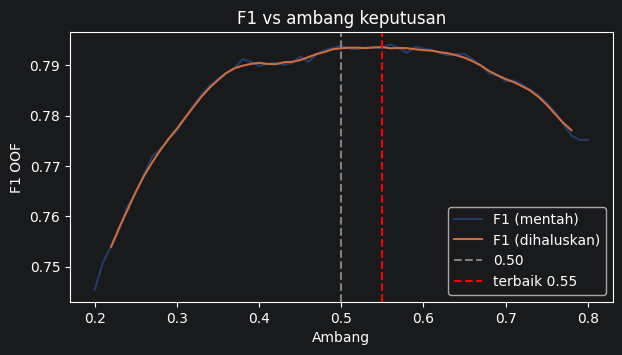

In [13]:
def search_threshold(y_true, probs, lo=0.2, hi=0.8, step=0.01):   # fungsi: hitung F1 untuk banyak ambang
    ths = np.arange(lo, hi + 1e-9, step)                          #   daftar ambang kandidat 0.20 … 0.80
    scores = np.array([f1_score(y_true, (probs >= t).astype(int)) for t in ths])   # F1 tiap ambang
    return ths, scores                                            #   kembalikan keduanya

ths, scores = search_threshold(y, oof_blend)                      # hitung kurva F1 vs ambang pada OOF ensemble

k = 5                                                             # lebar jendela penghalusan
smooth = np.convolve(scores, np.ones(k) / k, mode="same")         # rata-rata bergerak (peredam kegerigian)
smooth[: k // 2] = -1                                             # abaikan tepi kiri (efek batas konvolusi)
smooth[-(k // 2):] = -1                                           # abaikan tepi kanan
best_t = float(ths[smooth.argmax()])                              # ambang dengan F1 halus tertinggi
best_f1 = f1_score(y, (oof_blend >= best_t).astype(int))          # F1 OOF pada ambang tersebut

print(f"Ambang terbaik = {best_t:.2f} | F1 OOF = {best_f1:.4f} (vs {f1_default:.4f} pada 0.50)")   # hasil
if abs(best_t - 0.5) > 0.15:                                      # ambang terlalu jauh dari 0.5?
    print("⚠️ Ambang jauh dari 0.5 — hati-hati; bandingkan juga submission ambang 0.5.")   # peringatan

plt.figure(figsize=(7, 3.5))                                      # kanvas grafik
plt.plot(ths, scores, alpha=0.4, label="F1 (mentah)")             # kurva mentah (pucat)
plt.plot(ths, np.where(smooth < 0, np.nan, smooth), label="F1 (dihaluskan)")   # kurva halus (tepi disembunyikan)
plt.axvline(0.5, ls="--", c="gray", label="0.50")                 # garis ambang bawaan
plt.axvline(best_t, ls="--", c="red", label=f"terbaik {best_t:.2f}")   # garis ambang terpilih
plt.xlabel("Ambang"); plt.ylabel("F1 OOF"); plt.legend(); plt.title("F1 vs ambang keputusan")   # label & judul
plt.show()                                                        # tampilkan

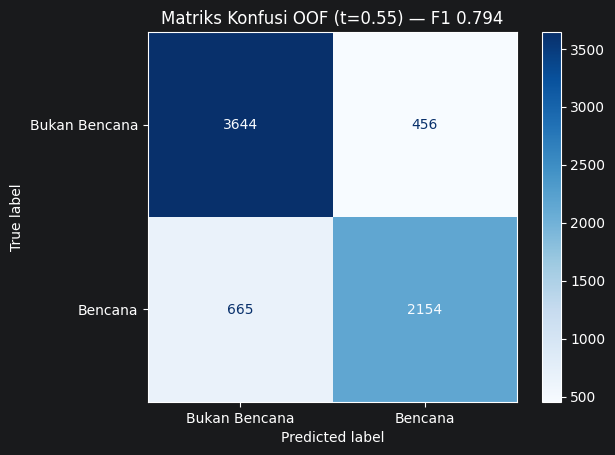

In [14]:
disp = ConfusionMatrixDisplay.from_predictions(                   # confusion matrix OOF pada ambang terpilih
    y, (oof_blend >= best_t).astype(int),                         #   label asli vs prediksi
    display_labels=["Bukan Bencana", "Bencana"], cmap=plt.cm.Blues)   # nama sumbu & warna
disp.ax_.set_title(f"Matriks Konfusi OOF (t={best_t:.2f}) — F1 {best_f1:.3f}")   # judul
plt.show()                                                        # tampilkan

## 7.3 Analisis kesalahan (opsional tapi sangat berguna)
Melihat tweet yang **paling meleset** sering membuka pola: label yang meragukan, sarkasme, kata kunci menyesatkan, dsb. Tabel di bawah menampilkan tweet dengan selisih terbesar antara probabilitas ensemble dan label asli.

In [15]:
err = df_train.copy()                                             # salin tabel train bersih
err["p_bencana"] = oof_blend                                     # tambah kolom probabilitas OOF
err["galat_mutlak"] = np.abs(err["target"] - err["p_bencana"])        # besar kesalahan = |label − probabilitas|
pd.set_option("display.max_colwidth", 120)                        # tampilkan teks lebih panjang
err.sort_values("galat_mutlak", ascending=False)[["keyword", "text", "target", "p_bencana"]].head(15).round(3)   # 15 kesalahan terbesar

,keyword,text,target,p_bencana
2664,drought,Large rain drops falling in Rock Hill off Anderson Road. #rain #scwx #drought,0,0.961
2773,dust%20storm,@NWSPocatello BG-16: So far brunt of storm just to our north. Grayed out w/ dust &amp; rain to N blue sky interspers...,0,0.956
6758,wounded,@AsterPuppet wounded and carried her back to where his brothers and sisters were and entered the air ship to go back...,0,0.956
4732,nuclear%20reactor,A little filming inside a Nuclear Reactor at #Chernobyl @SonyProUSA @LumixUSA @DJIGlobal @ProfBrianCox @RT_America h...,0,0.956
70,accident,#stlouis #caraccidentlawyer Speeding Among Top Causes of Teen Accidents https://t.co/k4zoMOF319 https://t.co/S2kXVM0...,0,0.956
3664,flooding,@adorableappple No reported flooding po in the area. Ten-4. #mmda,0,0.955
2443,destruction,Truck Driver Salvages Banned Tomatoes From Destruction on #Russian Border http://t.co/7b2Wf6ovFK #news,0,0.954
4031,hijacker,San Jose Mercury: Governor Brown allows parole for California school bus hijacker http://t.co/GpCeCp9kHv,0,0.954
6406,typhoon,Satellite Spies Super Typhoon Soudelor from Space (Photo) http://t.co/VBhu2t8wgB,0,0.953
5788,suicide%20bomb,@FoxNewsInsider All Obama is doing is giving a false time schedule on Iran testing there first bomb Bomb = Nucl...,0,0.952


# 8. Membuat file submission

Kita simpan **dua** file agar bisa dibandingkan di Kaggle:

| File | Ambang | Kapan dipakai |
|---|---|---|
| `submission.csv` | ambang hasil optimasi OOF | Kandidat utama |
| `submission_t050.csv` | 0.50 | Pembanding yang lebih "aman" |

> 💡 Kaggle membatasi jumlah submission per hari (umumnya 5). Kirim yang utama dulu; kirim yang kedua hanya bila perlu membandingkan.
> ⚠️ Jika `DEBUG = True`, file ditulis dengan akhiran `_debug` agar tidak tertukar.

In [16]:
suffix = "_debug" if DEBUG else ""                                # tandai file jika mode debug

sub_main = pd.DataFrame({                                         # submission utama
    "id": df_test["id"],                                          #   id dari data test (urutan sama dengan prediksi)
    "target": (test_blend >= best_t).astype(int),                 #   1 jika probabilitas ≥ ambang terpilih
})
sub_050 = pd.DataFrame({                                          # submission pembanding
    "id": df_test["id"],                                          #   id
    "target": (test_blend >= 0.5).astype(int),                    #   ambang standar 0.5
})

sub_main.to_csv(f"submission{suffix}.csv", index=False)           # simpan submission utama
sub_050.to_csv(f"submission_t050{suffix}.csv", index=False)       # simpan submission ambang 0.5

print("Proporsi kelas 1 — utama:", sub_main["target"].mean().round(3), "| t=0.5:", sub_050["target"].mean().round(3))   # cek sebaran
print("Jumlah baris berbeda antar-dua file:", int((sub_main["target"] != sub_050["target"]).sum()))   # seberapa beda keduanya
sub_main.head()                                                   # intip hasil

Proporsi kelas 1 — utama: 0.388 | t=0.5: 0.402
Jumlah baris berbeda antar-dua file: 46


,id,target
0,0,1
1,2,1
2,3,1
3,9,1
4,11,1


# 9. Langkah berikutnya

## 9.1 Cara memakai notebook ini secara bertahap

- [ ] Jalankan dengan `DEBUG = True` → pastikan tidak ada error.
- [ ] Jalankan penuh (`DEBUG = False`), submit `submission.csv`, catat skornya.
- [ ] Bandingkan dengan `submission_t050.csv` bila skor aneh.
- [ ] Coba ensemble lebih besar (di bawah).

## 9.2 Ide peningkatan lanjutan

| Ide | Cara | Catatan |
|---|---|---|
| **Tambah model berbeda** | `MODEL_NAMES = ["roberta-base", "microsoft/deberta-v3-base"]` | Keragaman arsitektur biasanya memberi peningkatan ensemble terbesar. DeBERTa-v3 butuh `sentencepiece`; bila fp16 bermasalah, jalankan tanpa AMP |
| **Model khusus Twitter** | `"vinai/bertweet-base"` | Dilatih di jutaan tweet; butuh paket `emoji` & mungkin `use_fast=False` pada tokenizer |
| **Tambah seed** | `SEEDS = [42, 7, 2024]` | Waktu naik linear; mengurangi variansi |
| **Model lebih besar** | `"roberta-large"` | Lebih kuat tapi lebih tidak stabil dan jauh lebih lambat; butuh batch/LR lebih kecil |
| **Peluruhan LR per lapisan** (*layer-wise LR decay*) | LR lebih kecil untuk layer bawah | Sering membantu pada data kecil |
| **Pelabelan semu** (*pseudo-labeling*) | Tambahkan tweet test berkeyakinan tinggi sebagai data latih | Berisiko memperkuat kesalahan; pakai ambang ketat |
| **Augmentasi saat pengujian** (*test-time augmentation*) | Rata-ratakan prediksi dengan/tanpa keyword | Murah, peningkatan kecil |
| **Pencocokan duplikat train↔test** | Tweet test yang sama dengan train → pakai label train | Efektif tetapi bersifat "memanfaatkan data", pertimbangkan sendiri etikanya |

## 9.3 Pemecahan masalah

| Gejala | Kemungkinan penyebab | Solusi |
|---|---|---|
| `CUDA out of memory` | Batch/MAX_LEN terlalu besar | Turunkan `BATCH_SIZE` ke 8 atau `MAX_LEN` ke 64 |
| Pengunduhan model gagal | Tidak ada internet | Siapkan folder model lokal & isi `LOCAL_DIRS` |
| Loss `nan` | fp16 tidak stabil (sering di DeBERTa) | Matikan AMP: `use_amp = False` |
| F1 per fold sangat bervariasi (std > 0.02) | Data kecil, fine-tuning tidak stabil | Tambah seed; turunkan `LR` ke 1e-5 |
| Waktu terlalu lama | Terlalu banyak model×seed×fold | Kurangi `N_FOLDS` atau `SEEDS` |